In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:150% !important; }</style>"))
import warnings
warnings.simplefilter('ignore')

In [2]:
import pandas as pd

import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
import time
from datetime import datetime, timedelta, date
import teradata
import  businessdays as bzd



system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");



select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

data_inicial = cal.offset(datetime.now(),-120  )###DATA PADRÃO D-60
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-90

data_final = cal.offset(datetime.now(),-1  )###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1


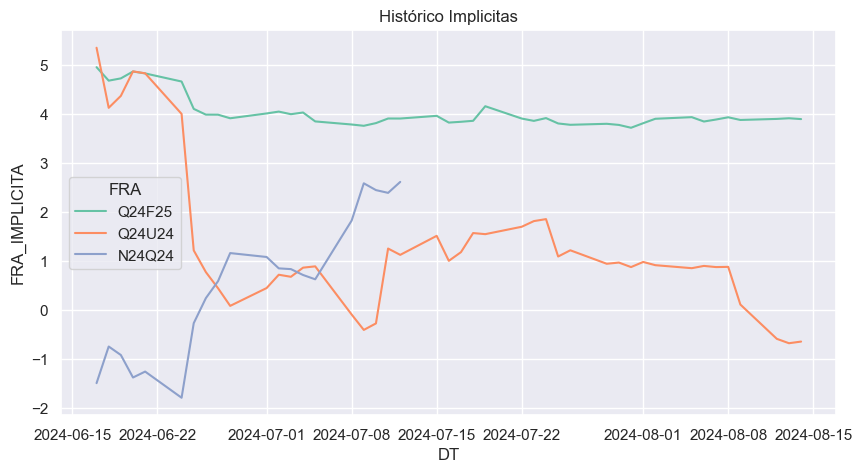

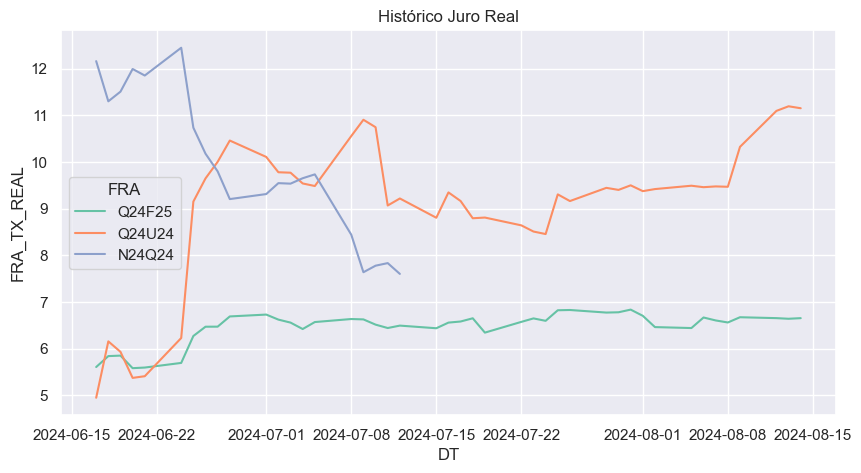

In [3]:
################### FRAS CURTISSIMAS PELO DAP #######################
 
 
Select  = f"""SELECT DT, FRA, FRA_IMPLICITA*100 AS FRA_IMPLICITA, FRA_TX_REAL*100 AS FRA_TX_REAL FROM DL_gESTAO_RECURSOS.VW_FRA_IMPLICITA_DAP INF
WHERE INF.DT between '{data_inicial}' and '{data_final}'
 
order by inf.dt asc"""
 
df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
pd.set_option('mode.chained_assignment', None)
 
 
df_grafico  = df[df['FRA'].isin(['M24N24','N24Q24','Q24U24','Q24F25'])]
df_grafico = df_grafico.sort_values(by=['DT'])
 
 
plot.rcParams['figure.figsize'] = (10,5)
sns.set(style="darkgrid", palette="Set2")
f = plot.figure(1)
sns.lineplot(x='DT', y='FRA_IMPLICITA', data=df_grafico, hue='FRA').set(title='Histórico Implicitas')
g = plot.figure(2)
sns.lineplot(x='DT', y='FRA_TX_REAL', data=df_grafico, hue='FRA').set(title='Histórico Juro Real')
f.show()
g.show()



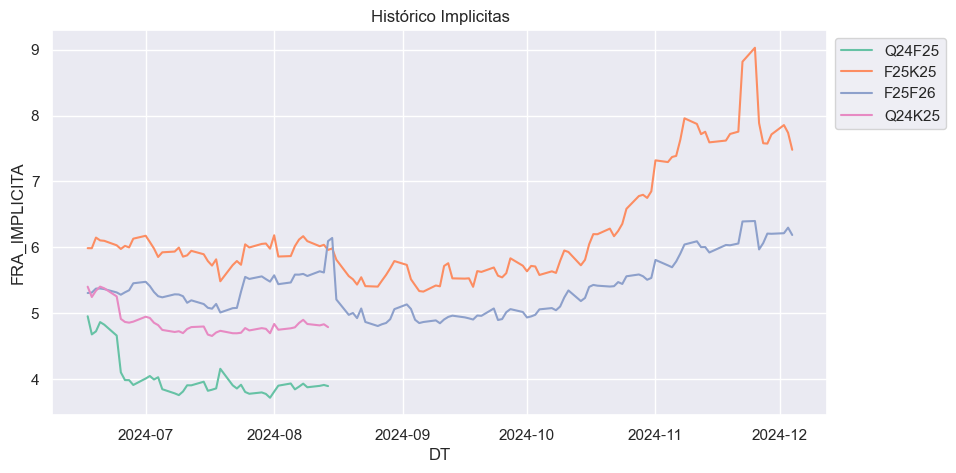

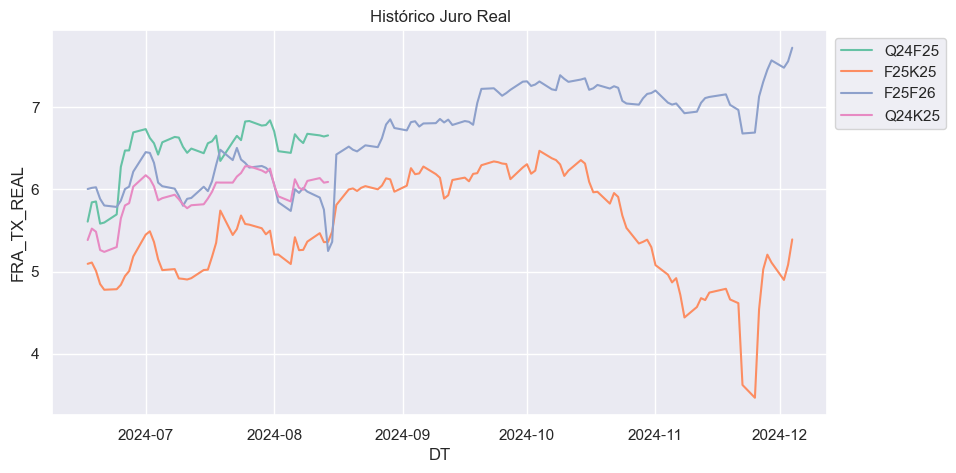

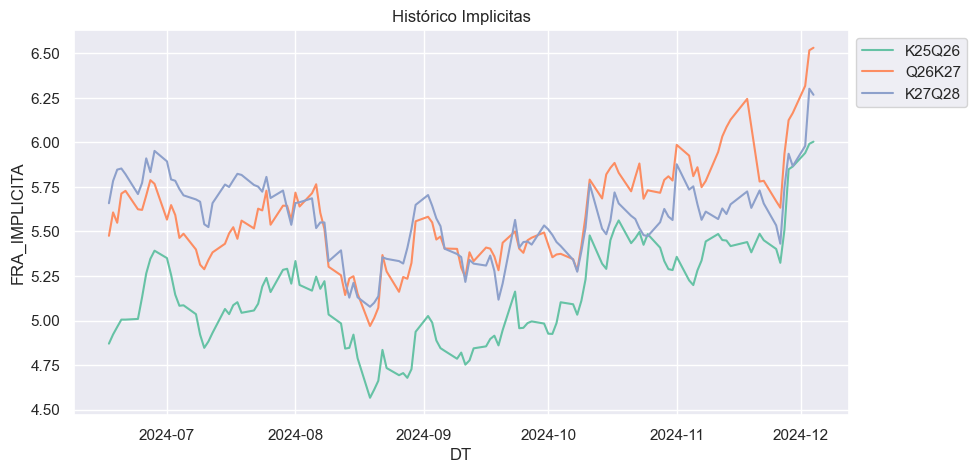

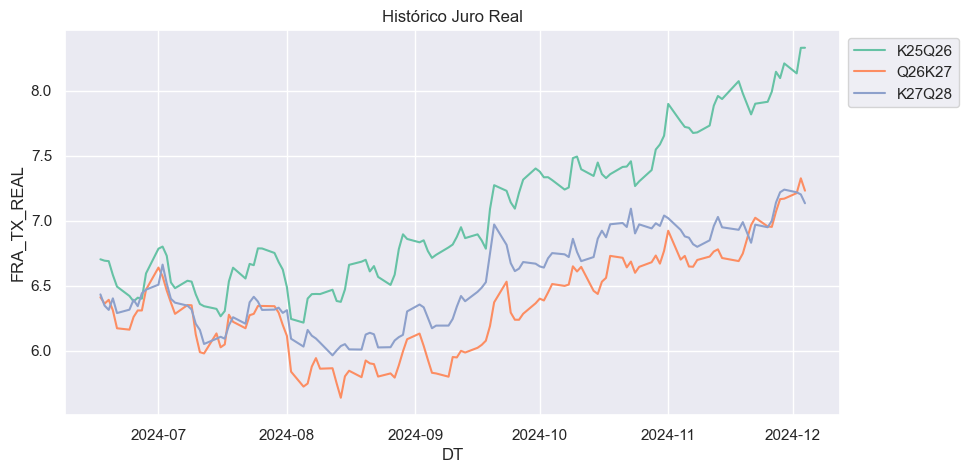

In [4]:
################### FRAS CURTAS PELO DAP #######################
 
df_grafico  = df[df['FRA'].isin(['M24Q24','Q24F25','Q24K25','F25K25','F25F26'])]
df_grafico = df_grafico.sort_values(by=['DT'])


plot.rcParams['figure.figsize'] = (10,5)
sns.set(style="darkgrid", palette="Set2")
o = plot.figure()
sns.lineplot(x='DT', y='FRA_IMPLICITA', data=df_grafico, hue='FRA').set(title='Histórico Implicitas')
plot.legend(loc=2, bbox_to_anchor=(1, 1))
p = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_REAL', data=df_grafico, hue='FRA').set(title='Histórico Juro Real')
plot.legend(loc=2, bbox_to_anchor=(1, 1))
o.show()
p.show()


df_grafico  = df[df['FRA'].isin(['K25Q26','Q26K27','K27Q28'])]
df_grafico = df_grafico.sort_values(by=['DT'])


plot.rcParams['figure.figsize'] = (10,5)
sns.set(style="darkgrid", palette="Set2")
oo = plot.figure()
sns.lineplot(x='DT', y='FRA_IMPLICITA', data=df_grafico, hue='FRA').set(title='Histórico Implicitas')
plot.legend(loc=2, bbox_to_anchor=(1, 1))
po = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_REAL', data=df_grafico, hue='FRA').set(title='Histórico Juro Real')
plot.legend(loc=2, bbox_to_anchor=(1, 1))
oo.show()
po.show()


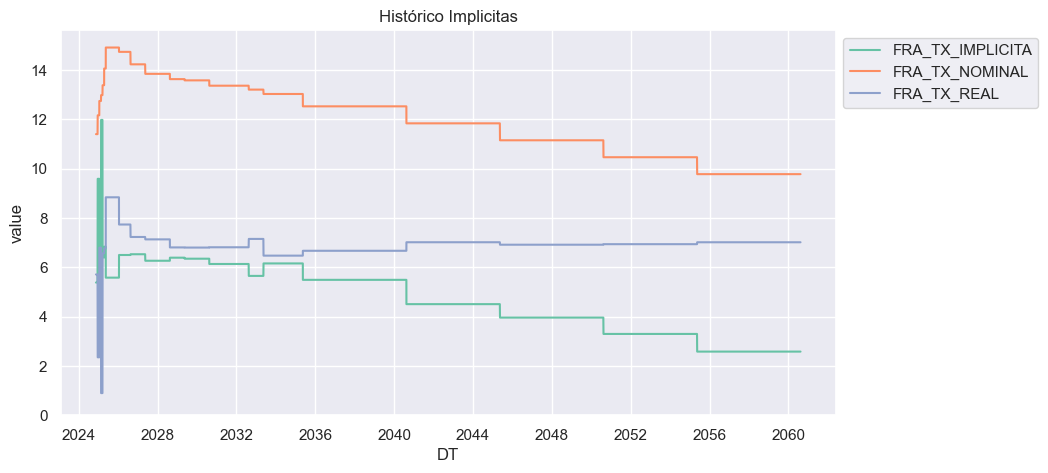

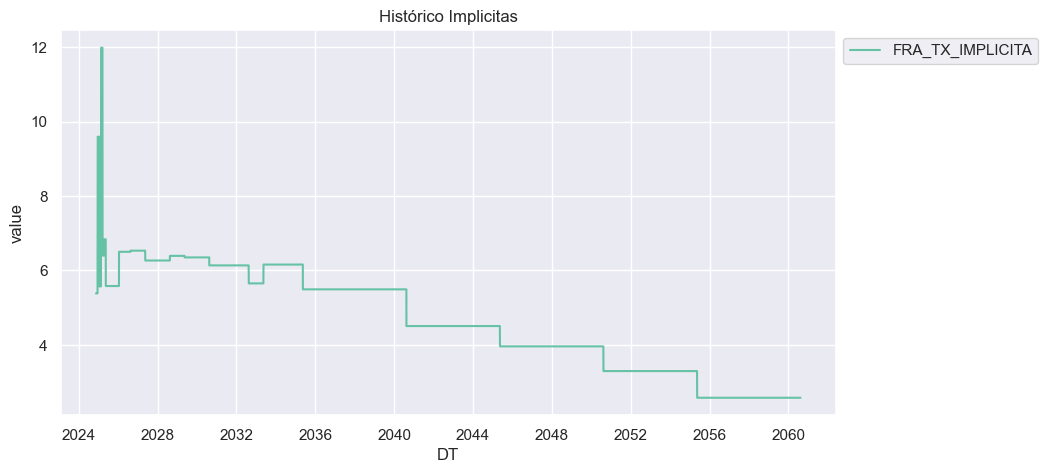

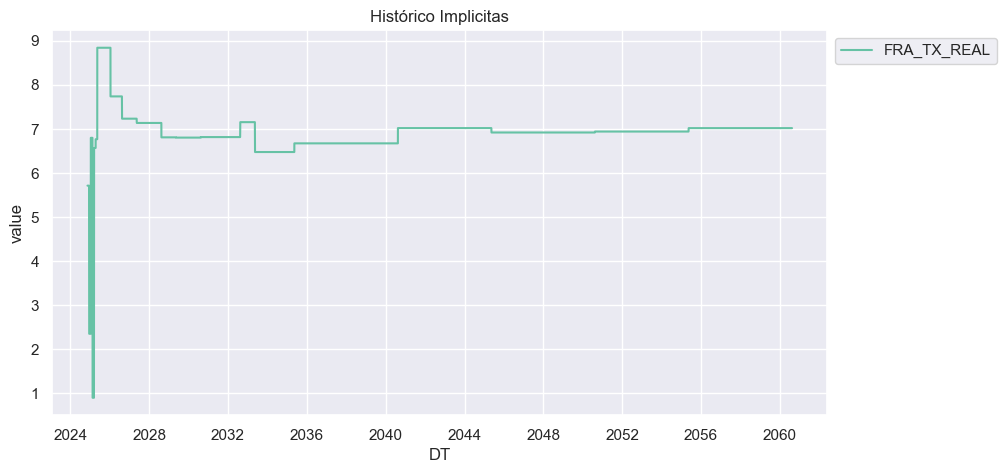

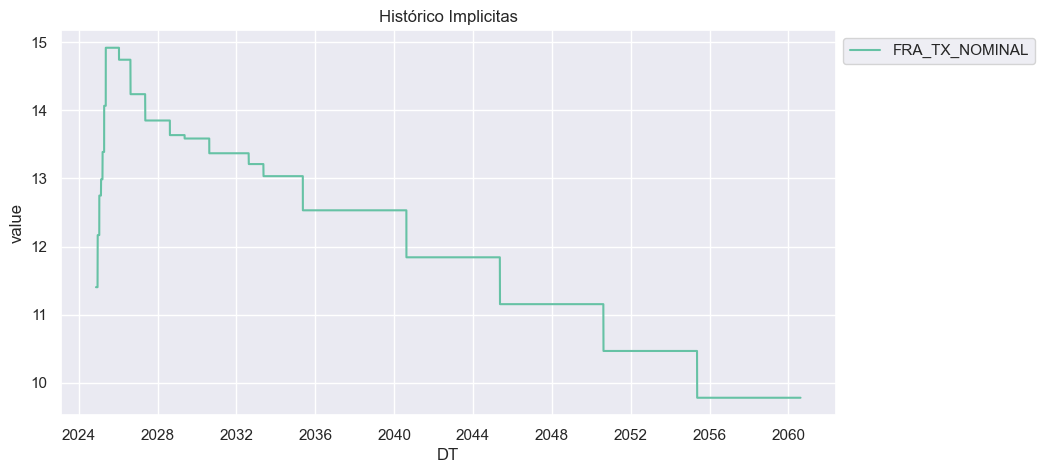

In [5]:

################### FRAS pelo DAP #######################

Select  = f"""SELECT 
            DU.DT
            ,INF.DT_VENCIMENTO, FRA_TX_REAL*100 AS FRA_TX_REAL, FRA_IMPLICITA*100 AS FRA_TX_IMPLICITA
            , ((1+FRA_TX_REAL)*(1+FRA_IMPLICITA)-1)*100 AS FRA_TX_NOMINAL 
            
            FROM DL_gESTAO_RECURSOS.VW_FRA_IMPLICITA_DAP INF
            INNER JOIN DL_GESTAO_RECURSOS.DU ON DU.DT_PX1 = INF.dt_VENCIMENTO OR DU.DT = INF.DT_VENCIMENTO_ANT
            LEFT JOIN DL_GESTAO_RECURSOS.DU DUB ON DU.DT_ANT1 = INF.DT
            WHERE inf.dt = '{data_final}'
            AND RANKING = 1 AND FRA_TX_REAL <0.20 AND FRA_IMPLICITA <0.20
            ORDER BY DU.DT
                """

df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
pd.set_option('mode.chained_assignment', None)

df_grafico  = df
#df_grafico= pd.melt(df_grafico[['VENCIMENTO','TX_IMPLICITA','TX_NOMINAL', 'TX_REAL']], ['VENCIMENTO'])
df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico  = df_grafico.sort_values(by=['DT'])

plot.rcParams['figure.figsize'] = (10,5)

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='value', data=df_grafico, hue='variable').set(title='Histórico Implicitas')
plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()





################### FRAS IMPLICITAS pelo DAP #######################

df_grafico  = df
#df_grafico= pd.melt(df_grafico[['VENCIMENTO','TX_IMPLICITA','TX_NOMINAL', 'TX_REAL']], ['VENCIMENTO'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico  = df_grafico.sort_values(by=['DT'])

plot.rcParams['figure.figsize'] = (10,5)

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='value', data=df_grafico, hue='variable').set(title='Histórico Implicitas')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()

df_grafico  = df
#df_grafico= pd.melt(df_grafico[['VENCIMENTO','TX_IMPLICITA','TX_NOMINAL', 'TX_REAL']], ['VENCIMENTO'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico= pd.melt(df_grafico[['DT','FRA_TX_REAL']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico  = df_grafico.sort_values(by=['DT'])

plot.rcParams['figure.figsize'] = (10,5)

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='value', data=df_grafico, hue='variable').set(title='Histórico Implicitas')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()



################### FRAS NOMINAL pelo DAP #######################

df_grafico  = df
#df_grafico= pd.melt(df_grafico[['VENCIMENTO','TX_IMPLICITA','TX_NOMINAL', 'TX_REAL']], ['VENCIMENTO'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico= pd.melt(df_grafico[['DT','FRA_TX_NOMINAL']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico  = df_grafico.sort_values(by=['DT'])

plot.rcParams['figure.figsize'] = (10,5)

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='value', data=df_grafico, hue='variable').set(title='Histórico Implicitas')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()



In [6]:
data = data_final

data_a = cal.offset(data,-5).strftime('%Y-%m-%d') ###DATA PADRÃO D-1
data_b = cal.offset(data,-21).strftime('%Y-%m-%d') ###DATA PADRÃO D-1
data_c = cal.offset(data,-63).strftime('%Y-%m-%d') ###DATA PADRÃO D-1
data_d = cal.offset(data,-126).strftime('%Y-%m-%d') ###DATA PADRÃO D-1
data_final = cal.offset(cal.offset(data,-2  ),1) ###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

In [7]:
################### FRAS pelo DAP #######################

Select  = f"""SELECT 
            DU.DT
            ,INF.DT_VENCIMENTO, FRA_TX_REAL*100 AS FRA_TX_REAL, FRA_IMPLICITA*100 AS FRA_TX_IMPLICITA
            , ((1+FRA_TX_REAL)*(1+FRA_IMPLICITA)-1)*100 AS FRA_TX_NOMINAL 
            , INF.DT AS DT_REF
            FROM DL_gESTAO_RECURSOS.VW_FRA_IMPLICITA_DAP INF
            INNER JOIN DL_GESTAO_RECURSOS.DU ON DU.DT_PX1 = INF.dt_VENCIMENTO OR DU.DT = INF.DT_VENCIMENTO_ANT
            LEFT JOIN DL_GESTAO_RECURSOS.DU DUB ON DU.DT_ANT1 = INF.DT
            WHERE inf.dt IN  in ('2024-07-12')
            AND FRA IN ('Q24','Q24F25','F25K25','K25Q26','Q26K27','K27Q28','Q28Q30'
            ,'Q30K33','K33K35','K35Q40','Q40K45','K45Q50','Q50K55', 'K55Q60'
            )
            ORDER BY DU.DT
                """

df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
pd.set_option('mode.chained_assignment', None)

df_grafico  = df
#df_grafico= pd.melt(df_grafico[['VENCIMENTO','TX_IMPLICITA','TX_NOMINAL', 'TX_REAL']], ['VENCIMENTO'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico  = df_grafico.sort_values(by=['DT', 'DT_REF'])
df_grafico.DT_REF = df_grafico.DT_REF.astype(str)
plot.rcParams['figure.figsize'] = (10,5)

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_IMPLICITA', data=df_grafico, hue='DT_REF').set(title='Histórico Implicitas')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()


sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_REAL', data=df_grafico, hue='DT_REF').set(title='Histórico Taxa Real')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_NOMINAL', data=df_grafico, hue='DT_REF').set(title='Histórico Taxa Nominal')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()



DatabaseError: Execution failed on sql 'SELECT 
            DU.DT
            ,INF.DT_VENCIMENTO, FRA_TX_REAL*100 AS FRA_TX_REAL, FRA_IMPLICITA*100 AS FRA_TX_IMPLICITA
            , ((1+FRA_TX_REAL)*(1+FRA_IMPLICITA)-1)*100 AS FRA_TX_NOMINAL 
            , INF.DT AS DT_REF
            FROM DL_gESTAO_RECURSOS.VW_FRA_IMPLICITA_DAP INF
            INNER JOIN DL_GESTAO_RECURSOS.DU ON DU.DT_PX1 = INF.dt_VENCIMENTO OR DU.DT = INF.DT_VENCIMENTO_ANT
            LEFT JOIN DL_GESTAO_RECURSOS.DU DUB ON DU.DT_ANT1 = INF.DT
            WHERE inf.dt IN  in ('2024-07-12')
            AND FRA IN ('Q24','Q24F25','F25K25','K25Q26','Q26K27','K27Q28','Q28Q30'
            ,'Q30K33','K33K35','K35Q40','Q40K45','K45Q50','Q50K55', 'K55Q60'
            )
            ORDER BY DU.DT
                ': (3706, "[42000] [Teradata][ODBC Teradata Driver][Teradata Database](-3706)Syntax error: expected something between the 'IN' keyword and the 'in' keyword.")

In [ ]:
################# FRAS NOMINAS PELO DI ################

Select  = f"""
            select DUC.DT, FRA.DT AS DT_REF, FRA.FRA, FRA.FRA_DU, FRA.CONTRATO_A, FRA.CONTRATO_B, FRA.TX_FRA , RANK() OVER (PARTITION BY CONTRATO_A, FRA.DT ORDER BY CONTRATO_B ASC) AS RANKING 
            from DL_GESTAO_RECURSOS.VW_FRA_VERTICE_FIXO FRA
            INNER JOIN DL_GESTAO_RECURSOS.DU ON DU.NUM = FRA.CONTRATO_B OR DU.NUM -1 = FRA.CONTRATO_A
            LEFT JOIN DL_GESTAO_RECURSOS.DU DUB ON DUB.DT_ANT1 = FRA.DT
            left join dl_gestao_recursos.du DUC ON DUB.NUM + DU.NUM = DUC.NUM
            where fra.dt in ('2024-01-02','2024-03-28','2024-05-31','{data_final}') AND FRA.FRA_DU IN ('21x42',
            '42x63',
            '63x126',
            '126x189',
            '189x252',
            '252x315',
            '315x378',
            '378x504',
            '504x630',
            '630x756',
            '756x882',
            '882x1008',
            '1008x1134',
            '1134x1260',
            '1260x1386',
            '1386x1512',
            '1512x1638',
            '1638x1764',
            '1764x1890',
            '1890x2016',
            '2016x2142',
            '2142x2268',
            '2268x2394',
            '2394x2520')
            """
df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
df.DT_REF = df.DT_REF.astype(str)
pd.set_option('mode.chained_assignment', None)

df_grafico  = df
df_grafico  = df_grafico.sort_values(by=['DT', 'DT_REF'])

plot.rcParams['figure.figsize'] = (10,5)

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='TX_FRA', data=df_grafico, hue='DT_REF').set(title='Histórico FRA Juros Nominais')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()

In [ ]:
       ['ggplot2', 'seaborn', 'simple_white', 'plotly',
         'plotly_white', 'plotly_dark', 'presentation', 'xgridoff',
         'ygridoff', 'gridon', 'none']

In [ ]:
import plotly.express as px
fig = px.line(df_grafico, x='DT', y='TX_FRA', color='DT_REF', template='seaborn')
#cor_suave = 'lightgreen'
#fig.update_traces(marker_color=cor_suave)
#cor_destacada = '#FF0000'  # Verde Sicredi

# Definindo a cor para a categoria destacada
#fig.update_traces(line=dict(color=[cor_destacada if 'DT_REF' == '2024-07-12' else ['#FF0000','#FF0000','#FF0000','#FF0000','#FF0000','#FF0000']]))

# Exibindo o gráfico
fig.show()

In [ ]:


################### FRAS pelo DAP #######################

Select  = f"""SELECT 
            DU.DT
            ,INF.DT_VENCIMENTO, FRA_TX_REAL*100 AS FRA_TX_REAL, FRA_IMPLICITA*100 AS FRA_TX_IMPLICITA
            , ((1+FRA_TX_REAL)*(1+FRA_IMPLICITA)-1)*100 AS FRA_TX_NOMINAL 
            , INF.DT AS DT_REF
            FROM DL_gESTAO_RECURSOS.VW_FRA_IMPLICITA_DAP INF
            INNER JOIN DL_GESTAO_RECURSOS.DU ON DU.DT_PX1 = INF.dt_VENCIMENTO OR DU.DT = INF.DT_VENCIMENTO_ANT
            LEFT JOIN DL_GESTAO_RECURSOS.DU DUB ON DU.DT_ANT1 = INF.DT
            WHERE inf.dt IN  ('2024-01-02','2024-03-28','2024-05-31','{data_final}')
            AND FRA IN ('Q24','Q24F25','F25K25','K25Q26','Q26K27','K27Q28','Q28Q30'
            ,'Q30K33','K33K35','K35Q40','Q40K45','K45Q50','Q50K55', 'K55Q60'
            )
            ORDER BY DU.DT
                """

df = pd.read_sql(Select, session) 
df.DT = pd.to_datetime(df.DT, format='%Y-%m-%d') 
pd.set_option('mode.chained_assignment', None)

df_grafico  = df
#df_grafico= pd.melt(df_grafico[['VENCIMENTO','TX_IMPLICITA','TX_NOMINAL', 'TX_REAL']], ['VENCIMENTO'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT','FRA_TX_IMPLICITA']], ['DT'])
#df_grafico= pd.melt(df_grafico[['DT', 'FRA_TX_REAL', 'FRA_TX_NOMINAL']], ['DT'])
df_grafico  = df_grafico.sort_values(by=['DT', 'DT_REF'])
df_grafico.DT_REF = df_grafico.DT_REF.astype(str)
plot.rcParams['figure.figsize'] = (10,5)

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_IMPLICITA', data=df_grafico, hue='DT_REF').set(title='Histórico Implicitas')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()


sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_REAL', data=df_grafico, hue='DT_REF').set(title='Histórico Taxa Real')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()

sns.set(style="darkgrid", palette="Set2")
f = plot.figure()
sns.lineplot(x='DT', y='FRA_TX_NOMINAL', data=df_grafico, hue='DT_REF').set(title='Histórico Taxa Nominal')
#plot.ylim(0)
plot.legend(loc=2, bbox_to_anchor=(1, 1))
f.show()

